## 1. Imports and Data Loading

In [115]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from rapidfuzz import process, fuzz

In [116]:
df = pd.read_csv('hotel_playa_serena_bookings_dirty.csv')

## 2. Initial Dataset Exploration

In [117]:
df.head(20)

,Unnamed: 0,Booking_ID,Booking_Date,Arrival_Date,Departure_Date,Day_of_Week,Season,Is_Weekend,Event_Type,Event_Name,...,RevPAR,Distribution_Channel,Market_Segment,Length_of_Stay,Lead_Time_Days,Is_Cancelled,Is_Walk_in,Nationality,Room_Type,Rate_Plan
0,8726,HPS-108727,2025-08-03,2025-10-18,2025-10-23,Saturday,Medium,True,NaN,NaN,...,85.57,Expedia,Leisure/Vacation,5,76,False,False,Germany,DELUXE SEA VIEW,BAR (Flexible Rate)
1,4884,HPS-104885,2025-04-13,2025-05-29,2025-06-02,Thursday,Mdium,False,NaN,NaN,...,57.23,GDS,groups,4,46,False,False,Netherlands,Superioor,All Inclusive
2,5023,HPS-105024,2025-03-29,2025-06-03,2025-06-11,Tuesday,High,False,NaN,NaN,...,248.79,Booking.com,Leisure/Vacation,8,66,False,False,Nordic Countries,Swim-up,Non-Refundable
3,468,HPS-100469,2024-12-25,2025-01-11,2025-01-13,Saturday,Low,True,NaN,NaN,...,20.10,Direct (Web/Phone),Groups,2,17,False,False,Other,Family Suite,BAR (Flexible Rate)
4,9148,HPS-109149,2025-09-04,2025-10-31,2025-11-02,Friday,Medium,True,NaN,NaN,...,87.86,Tour Operator,Leisure/Vacation,2,57,False,No,france,Swim-up,Half Board
5,7334,HPS-107335,2025-04-03,2025-08-31,2025-09-12,Sunday,High,False,NaN,NaN,...,185.94,Travel Agency,Weddings/Events,12,150,False,No,GERMNAY,Deluxe Sea View,All Inclusive
6,1864,HPS-101865,2025-01-07,2025-02-23,24/02/2025,Sunday,ow,False,NaN,NaN,...,12.48,Booknig.com,Weddings/Events,1,47,True,False,United Kingdom,Superior,ABR (Flexible Rate)
7,3208,HPS-103209,2025-03-31,2025-04-07,2025-04-10,Monday,Meedium,False,NaN,NaN,...,85.26,GDS,Groups,3,7,False,False,Germany,Standard,ALL INCLUSIVE
8,6158,HPS-106159,2025-02-21,2025-07-16,2025-07-24,Wednesday,High,False,NaN,NaN,...,137.82,Direct (We/bPhone),Tour Operato/Contracted,8,145,False,False,Italy,Deluxe Sea View,Earlly Booking Offer
9,3693,HPS-103694,2025-02-26,22-Apr-2025,25-Apr-2025,Tuesday,Mediumm,False,NaN,NaN,...,117.73,GDS,weddings/events,3,55,No,False,Other,Delluxe Sea View,BBAR (Flexible Rate)


In [118]:
df.info()
df.shape
df.columns

<class 'pandas.DataFrame'>
RangeIndex: 11691 entries, 0 to 11690
Data columns (total 25 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Unnamed: 0            11691 non-null  int64  
 1   Booking_ID            11691 non-null  str    
 2   Booking_Date          11691 non-null  str    
 3   Arrival_Date          11691 non-null  str    
 4   Departure_Date        11691 non-null  str    
 5   Day_of_Week           11691 non-null  str    
 6   Season                11691 non-null  str    
 7   Is_Weekend            11691 non-null  bool   
 8   Event_Type            1770 non-null   str    
 9   Event_Name            1770 non-null   str    
 10  Rooms_Available       11691 non-null  int64  
 11  Rooms_Sold            11691 non-null  int64  
 12  Occupancy_%           11691 non-null  str    
 13  ADR                   11691 non-null  str    
 14  Room_Revenue          11691 non-null  float64
 15  RevPAR                11691 no

Index(['Unnamed: 0', 'Booking_ID', 'Booking_Date', 'Arrival_Date',
       'Departure_Date', 'Day_of_Week', 'Season', 'Is_Weekend', 'Event_Type',
       'Event_Name', 'Rooms_Available', 'Rooms_Sold', 'Occupancy_%', 'ADR',
       'Room_Revenue', 'RevPAR', 'Distribution_Channel', 'Market_Segment',
       'Length_of_Stay', 'Lead_Time_Days', 'Is_Cancelled', 'Is_Walk_in',
       'Nationality', 'Room_Type', 'Rate_Plan'],
      dtype='str')

In [119]:
df[['Is_Walk_in', 'Nationality']].dtypes

Is_Walk_in     str
Nationality    str
dtype: object

## 3. Data Cleaning

In [120]:
df = df.drop(columns=['Unnamed: 0'], errors='ignore')

### 3.1. Type Conversion

In [121]:
for col in ['Booking_Date', 'Arrival_Date', 'Departure_Date']:
      df[col] = pd.to_datetime(df[col], errors='coerce', format='mixed')

In [122]:
for col in ['Occupancy_%', 'ADR', 'Lead_Time_Days']:
      df[col] = pd.to_numeric(df[col], errors='coerce')

In [123]:
df['Is_Cancelled'].unique()

<StringArray>
['False', 'True', 'No', 'Sí']
Length: 4, dtype: str

In [124]:
df['Is_Walk_in'].unique()

<StringArray>
['False', 'No', 'True', 'Sí']
Length: 4, dtype: str

In [125]:
bool_columns = ['Is_Cancelled', 'Is_Walk_in']

bool_map = {
    'True': True, 'False': False,
    'Sí': True, 'No': False,
    True: True, False: False,
}

for col in bool_columns:
    df[col] = df[col].astype(str).map(bool_map)

for col in bool_columns:
    df[col] = df[col].astype(bool)

In [126]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 11691 entries, 0 to 11690
Data columns (total 24 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   Booking_ID            11691 non-null  str           
 1   Booking_Date          11691 non-null  datetime64[us]
 2   Arrival_Date          11691 non-null  datetime64[us]
 3   Departure_Date        11691 non-null  datetime64[us]
 4   Day_of_Week           11691 non-null  str           
 5   Season                11691 non-null  str           
 6   Is_Weekend            11691 non-null  bool          
 7   Event_Type            1770 non-null   str           
 8   Event_Name            1770 non-null   str           
 9   Rooms_Available       11691 non-null  int64         
 10  Rooms_Sold            11691 non-null  int64         
 11  Occupancy_%           11272 non-null  float64       
 12  ADR                   11323 non-null  float64       
 13  Room_Revenue          11691

In [127]:
df.describe()

,Booking_Date,Arrival_Date,Departure_Date,Rooms_Available,Rooms_Sold,Occupancy_%,ADR,Room_Revenue,RevPAR,Length_of_Stay,Lead_Time_Days
count,11691,11691,11691,11691.000000,11691.000000,11272.000000,11323.000000,11691.000000,11691.000000,11691.000000,10986.000000
mean,2025-05-03 15:57:17.413395,2025-07-02 18:19:11.039261,2025-07-06 13:45:07.621247,197.531263,120.468651,60.359301,125.623084,627.645505,92.058960,3.973398,58.582924
min,2024-06-12 00:00:00,2025-01-01 00:00:00,2025-01-02 00:00:00,195.000000,38.000000,-99.000000,-374.440000,39.230000,12.480000,1.000000,-179.000000
25%,2025-02-02 00:00:00,2025-03-28 00:00:00,2025-03-29 00:00:00,196.000000,79.000000,40.400000,76.610000,154.290000,29.230000,2.000000,23.250000
50%,2025-03-19 00:00:00,2025-06-30 00:00:00,2025-07-06 00:00:00,198.000000,114.000000,57.610000,102.320000,347.340000,63.130000,3.000000,47.000000
75%,2025-08-17 00:00:00,2025-10-14 00:00:00,2025-10-18 00:00:00,199.000000,170.000000,86.270000,161.390000,872.850000,141.140000,6.000000,85.000000
max,2025-12-31 00:00:00,2025-12-31 00:00:00,2026-03-01 00:00:00,200.000000,198.000000,147.990000,410.740000,3928.980000,339.250000,14.000000,223.000000
std,NaN,NaN,NaN,1.668593,49.149643,26.671969,72.273911,656.921693,78.817548,2.470194,49.610025


In [128]:
for col in df.select_dtypes(include=['string', 'object']):
    df[col] = df[col].str.strip().str.title()

In [129]:
for col in df.select_dtypes(include=['object', 'string']):
    if col == 'Booking_ID':
        continue
    print(f'\n{col}:')
    print(df[col].unique())


Day_of_Week:
<StringArray>
['Saturday', 'Thursday', 'Tuesday', 'Friday', 'Sunday', 'Monday', 'Wednesday']
Length: 7, dtype: str

Season:
<StringArray>
[ 'Medium',   'Mdium',    'High',     'Low',      'Ow', 'Meedium', 'Mediumm',
   'Edium',     'Igh', 'Meddium',  'Mdeium',    'Loow',    'Llow',     'Lwo',
      'Lw',     'Hih',  'Meduim',   'Hiigh',  'Medimu',      'Lo',     'Olw',
 'Mmedium',    'Hihg',    'Loww',   'Higgh', 'Mediium',   'Highh',     'Hgh',
   'Meium',   'Medim',     'Hig',   'Mediu',    'Ihgh',   'Hhigh',   'Medum',
 'Mediuum',    'Hgih',  'Emdium',  'Meidum']
Length: 39, dtype: str

Event_Type:
<StringArray>
[        nan,   'Holiday',   'Concert',     'Sport',  'Congress',   'Congres',
    'Holidy',     'Faiir',  'Cultural',    'Concer',      'Port',  'Concerrt',
    'Hliday',  'Conrgess',      'Fair',    'Oncert',   'Holidya',    'Cocert',
  'Holidayy',  'Cooncert',   'Cogress',    'Hoiday',   'Conecrt',  'Holiiday',
   'Cnocert',    'Ssport',   'Hoilday',  'Conce

In [130]:
df['Room_Type'].unique()

<StringArray>
[ 'Deluxe Sea View',        'Superioor',          'Swim-Up',
     'Family Suite',         'Superior',         'Standard',
 'Delluxe Sea View',        'Standaard',          'Sandard',
          'Uperior',
 ...
          'Suerior',     'Famiyl Suite',    'Family Ssuite',
   'Deluxe Sa View',      'Family Uite',           'Swim-U',
      'Famil Suite',           'Swm-Up',    'Family Suitte',
     'Famliy Suite']
Length: 138, dtype: str

In [131]:
Room_Types = ['Family Suite', 'Standard', 'Deluxe Sea View', 'Superior', 'Swim-up']

In [132]:
df['Distribution_Channel'].unique()

<StringArray>
[            'Expedia',                 'Gds',         'Booking.Com',
  'Direct (Web/Phone)',       'Tour Operator',       'Travel Agency',
         'Booknig.Com',  'Direct (We/Bphone)',                   nan,
                 'Gsd',
 ...
         'Bookign.Com',       'Tour Opeartor',         'Bookin.Gcom',
  'Driect (Web/Phone)',       'Travel Agnecy', 'Direct (Wweb/Phone)',
      'Tour Ooperator',      'Toour Operator',        'Tor Operator',
      'Travell Agency']
Length: 176, dtype: str

In [133]:
Distribution_Channels = ['Expedia', 'Travel Agency', 'Booking.com', 'Tour Operator', 'Direct (Web/Phone)', 'Unknown', 'GDS']

df['Distribution_Channel'] = (df['Distribution_Channel'].replace({
    '': 'Unknown',
    'N/D': 'Unknown',
    '-': 'Unknown',
    'n/d': 'Unknown',
    'N/A': 'Unknown',
    'nan': 'Unknown',
    'Nan': 'Unknown'
})
.fillna('Unknown')
)

In [134]:
df['Season'].unique()

<StringArray>
[ 'Medium',   'Mdium',    'High',     'Low',      'Ow', 'Meedium', 'Mediumm',
   'Edium',     'Igh', 'Meddium',  'Mdeium',    'Loow',    'Llow',     'Lwo',
      'Lw',     'Hih',  'Meduim',   'Hiigh',  'Medimu',      'Lo',     'Olw',
 'Mmedium',    'Hihg',    'Loww',   'Higgh', 'Mediium',   'Highh',     'Hgh',
   'Meium',   'Medim',     'Hig',   'Mediu',    'Ihgh',   'Hhigh',   'Medum',
 'Mediuum',    'Hgih',  'Emdium',  'Meidum']
Length: 39, dtype: str

In [135]:
Seasons = ['Low', 'Medium', 'High']

In [136]:
df['Market_Segment'].unique()

<StringArray>
[         'Leisure/Vacation',                    'Groups',
           'Weddings/Events',   'Tour Operato/Contracted',
         'Leisuure/Vacation',                 'Corporate',
  'Tour Operator/Contracted',                'Corpporate',
         'Leisure/Vacationn',                 'Ocrporate',
 ...
 'Tour Operattor/Contracted', 'Tour Operator/Ccontracted',
  'Tour Operator/Ocntracted',  'Tour Poerator/Contracted',
   'Tor Operator/Contracted',  'Tour Operator/Contarcted',
 'Tour Operator/Contracteed',            'Weddings/Vents',
 'Tour Operator/Conttracted',  'Tour Operato/Rcontracted']
Length: 193, dtype: str

In [137]:
Market_Segments = ['Tour Operator/Contracted', 'Leisure/Vacation', 'Weddings/Events', 'Corporate', 'Groups', 'Unknown']

df['Market_Segment'] = (df['Market_Segment'].fillna('Unknown'))

In [138]:
df['Nationality'].unique()

<StringArray>
[          'Germany',       'Netherlands',  'Nordic Countries',
             'Other',            'France',           'Germnay',
    'United Kingdom',             'Italy',           'Unknown',
             'Spian',
 ...
 'Noordic Countries', 'Nordic Counttries',        'Netherlads',
 'Nordicc Countries',              'Othe',        'Neherlands',
  'Nordic Cuontries',   'Nordic Countrie', 'Nordic Ccountries',
 'Nordic Couuntries']
Length: 216, dtype: str

In [139]:
nationalities = ['Germany', 'France', 'Italy', 'United Kingdom', 'Nordic Countries', 'Netherlands', 'Belgium', 'Spain', 'Others', 'Unknown']

df['Nationality'] = (df['Nationality'].replace({
    '': 'Unknown',
    'N/D': 'Unknown',
    '-': 'Unknown',
    'n/d': 'Unknown',
    'N/A': 'Unknown',
    'nan': 'Unknown',
    'Nan': 'Unknown'
})
.fillna('Unknown')
)

In [140]:
df['Rate_Plan'].unique()

<StringArray>
[ 'Bar (Flexible Rate)',        'All Inclusive',       'Non-Refundable',
           'Half Board',  'Abr (Flexible Rate)', 'Earlly Booking Offer',
 'Bbar (Flexible Rate)',                    nan,  'Early Booking Offer',
                    '-',
 ...
           'Las Minute',           'Last Mnute',           'Last Miute',
   'Erly Booking Offer',      'Non-Refunndable',   'Arly Booking Offer',
 'Eearly Booking Offer',   'Early Booing Offer',  'Early Booking Ofefr',
         'Last Minnute']
Length: 224, dtype: str

In [141]:
Rate_Plans = ['Bar (Flexible Rate)', 'Half Board', 'Last Minute', 'Non-Refundable', 'Early Booking Offer', 'All Inclusive', 'Others', 'Unknown']

df['Rate_Plan'] = (df['Rate_Plan'].replace({
    '': 'Unknown',
    'N/D': 'Unknown',
    '-': 'Unknown',
    'n/d': 'Unknown',
    'N/A': 'Unknown',
    'nan': 'Unknown',
    'Nan': 'Unknown'
})
.fillna('Unknown')
)

In [142]:
df['Event_Type'].unique()

<StringArray>
[        nan,   'Holiday',   'Concert',     'Sport',  'Congress',   'Congres',
    'Holidy',     'Faiir',  'Cultural',    'Concer',      'Port',  'Concerrt',
    'Hliday',  'Conrgess',      'Fair',    'Oncert',   'Holidya',    'Cocert',
  'Holidayy',  'Cooncert',   'Cogress',    'Hoiday',   'Conecrt',  'Holiiday',
   'Cnocert',    'Ssport',   'Hoilday',  'Conceert',  'Concertt',   'Culturl',
    'Sportt',    'Spport',   'Congess',    'Spoort',  'Holliday',    'Cncert',
     'Sprot',   'Ocncert',      'Spor',  'Cconcert',   'Ongress',   'Hloiday',
   'Ultural',  'Holidday',   'Conress',      'Sort',   'Concret',   'Cocnert',
 'Culttural',   'Ohliday',  'Hooliday',    'Conert', 'Ccongress', 'Congreess',
    'Holday',  'Congerss',      'Fiar',  'Holidaay',   'Holiady',    'Holida',
  'Conncert',     'Spotr',     'Psort',      'Afir',  'Conccert', 'Congresss',
    'Holiay',   'Holdiay', 'Culturral',     'Ffair',   'Cltural', 'Conngress',
      'Sprt',  'Cutlural',   'Concetr'

In [143]:
Event_Types = ['Holiday', 'Concert', 'Sport', 'Cultural', 'Fair', 'Congress']

In [144]:
df['Event_Name'].unique()

<StringArray>
[                                nan,                         'Christmas',
                         'Holy Week',            'Mallorca Live Festival',
   'Real Malloorca Match (Son Moix)',   'Congress / Corporate Convention',
      'Assumption / Festes De Palma',                          'Epiphany',
    'Real Mallorca Match (Son Moix)', 'International Concert Palma Arena',
 ...
         'Sant Joan (St. John'S Ev)',                   'Nnew Year'S Eve',
   'Real Mallorca Mattch (Son Moix)',           'Concerrt Playa De Palma',
  'Intenational Concert Palma Arena',     'Eal Mallorca Match (Son Moix)',
                     'New Ear'S Eve',                         'Epiphanny',
              'Loca Lmusic Festival',                          'Hoy Week']
Length: 239, dtype: str

In [145]:
Event_Names = [
    'Christmas', 
    'Holy Week',
    'Mallorca Live Festival',
    'Real Mallorca Match (Son Moix)', 
    'Congress / Corporate Convention', 
    'Assumption / Festes de Palma',
    'Epiphany',
    'International Concert Palma Arena',
    'New Year\'s Day',
    'Christmas Eve',
    'Mallorca Marathon',
    'New Year\'s Eve',
    'Palma International Boat Show',
    "Rock the Coast Festival",
    "Local Music Festival",
    "Nit de l'Art - Art Night (Palma)",
    "Concert Playa de Palma",
    "DJ Set / Electronic Festival",
    "Sant Joan (St. John's Eve)",
    "Copa del Rey MAPFRE (Sailing)",
    "Sant Joan (Night of Fire)",
    "Holy Week (Easter)",
    "Fira del Ram - Palm Fair (Palma)",
]

### 3.2. Initial Visualization 

<Axes: >

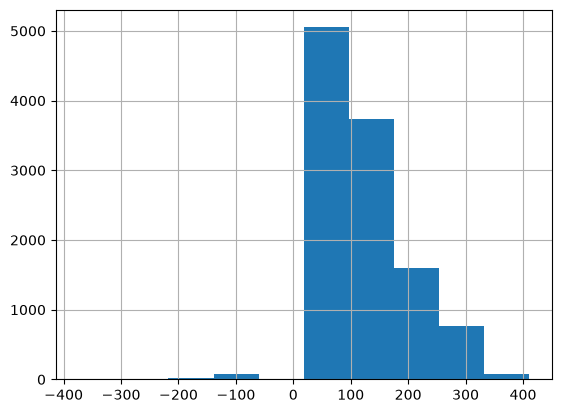

In [146]:
df['ADR'].hist()

<Axes: >

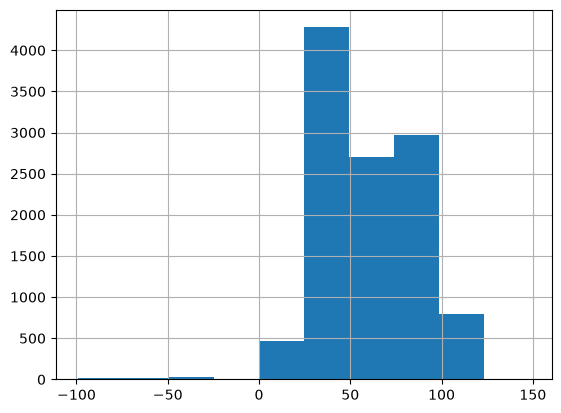

In [147]:
df['Occupancy_%'].hist()

<Axes: ylabel='Market_Segment'>

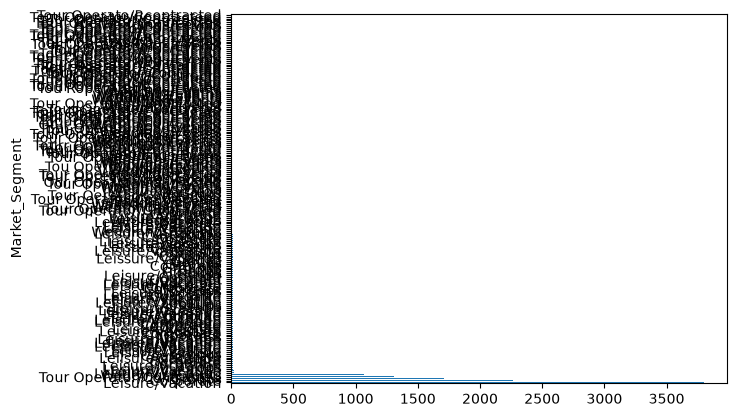

In [148]:
df['Market_Segment'].value_counts().plot.barh()

<Axes: >

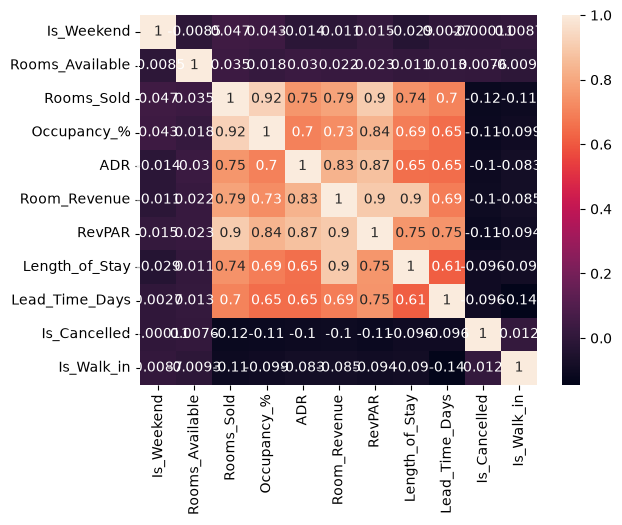

In [149]:
sns.heatmap(df.corr(numeric_only=True), annot=True)

### 3.3. Category Correction

In [150]:
normalizations = {
    'Nationality': nationalities,
    'Room_Type': Room_Types,
    'Distribution_Channel': Distribution_Channels,
    'Market_Segment': Market_Segments,
    'Rate_Plan': Rate_Plans,
    'Event_Type': Event_Types,
    'Event_Name': Event_Names,
    'Season': Seasons
}


def normalize(value, options, threshold=65):
    if pd.isna(value):
        return value

    match, score, _ = process.extractOne(value, options, scorer=fuzz.ratio)

    return match if score >= threshold else value

df['Nationality'] = df['Nationality'].apply(
    lambda x: normalize(x, nationalities)
)

df['Room_Type'] = df['Room_Type'].apply(
    lambda x: normalize(x, Room_Types)
)

df['Distribution_Channel'] = df['Distribution_Channel'].apply(
    lambda x: normalize(x, Distribution_Channels)
)

df['Market_Segment'] = df['Market_Segment'].apply(
    lambda x: normalize(x, Market_Segments)
)

df['Rate_Plan'] = df['Rate_Plan'].apply(
    lambda x: normalize(x, Rate_Plans)
)

df['Season'] = df['Season'].apply(
    lambda x: normalize(x, Seasons)
)

df['Event_Name'] = df['Event_Name'].apply(
    lambda x: normalize(x, Event_Names)
)

df['Event_Type'] = df['Event_Type'].apply(
    lambda x: normalize(x, Event_Types)
)


In [151]:
df['Nationality'].unique()

<StringArray>
[         'Germany',      'Netherlands', 'Nordic Countries',
           'Others',           'France',   'United Kingdom',
            'Italy',          'Unknown',            'Spain',
             'Ther',          'Belgium',            'Psain',
            'Tialy',            'Toher']
Length: 14, dtype: str

In [152]:
nationality_map = {
    'Ther': 'Other',
    'Tialy': 'Italy',
    'Other': 'Others',
    'Psain': 'Spain'
}

In [153]:
df['Nationality'] = df['Nationality'].replace(nationality_map)

In [154]:
df['Rate_Plan'].unique()

<StringArray>
['Bar (Flexible Rate)',       'All Inclusive',      'Non-Refundable',
          'Half Board', 'Early Booking Offer',             'Unknown',
         'Last Minute']
Length: 7, dtype: str

In [155]:
df['Is_Cancelled'].unique()

array([False,  True])

In [156]:
df['Room_Type'].unique()

<StringArray>
['Deluxe Sea View',        'Superior',         'Swim-up',    'Family Suite',
        'Standard',          'Wim-Up',         'Wsim-Up']
Length: 7, dtype: str

In [157]:
room_type_map = {
'Wim-Up': 'Swim-up',
'Wsim-Up': 'Swim-up'
}


In [158]:
df['Room_Type'] = df['Room_Type'].replace(room_type_map)

In [159]:
df['Market_Segment'].unique()

<StringArray>
[        'Leisure/Vacation',                   'Groups',
          'Weddings/Events', 'Tour Operator/Contracted',
                'Corporate']
Length: 5, dtype: str

In [160]:
df['Distribution_Channel'].unique()

<StringArray>
[           'Expedia',                'Gds',        'Booking.com',
 'Direct (Web/Phone)',      'Tour Operator',      'Travel Agency',
            'Unknown',                'Gsd',               'Ggds',
               'Gdss',                 'Gd',                 'Ds',
                 'Gs',                'Dgs',               'Gdds']
Length: 15, dtype: str

In [161]:
distribution_channel_map = {
    'Gsd': 'GDS',
    'Gds': 'GDS',
    'Gd': 'GDS',
    'Dgs': 'GDS',
    'Gdss': 'GDS',
    'Gs': 'GDS',
    'Ggds': 'GDS',
    'Gdds': 'GDS',
    'Ds': 'GDS'
    }


In [162]:
df['Distribution_Channel'] = df['Distribution_Channel'].replace(distribution_channel_map)

In [163]:
df['Season'].unique()

<StringArray>
['Medium', 'High', 'Low', 'Ow', 'Igh', 'Olw', 'Ihgh']
Length: 7, dtype: str

In [164]:
season_map = {
    'Ow': 'Low',
    'Igh': 'High',
    'Olw': 'Low',
    'Ihgh': 'High'
}

In [165]:
df['Season'] = df['Season'].replace(season_map)

In [166]:
df['Event_Name'].unique()

<StringArray>
[                                nan,                         'Christmas',
                         'Holy Week',            'Mallorca Live Festival',
    'Real Mallorca Match (Son Moix)',   'Congress / Corporate Convention',
      'Assumption / Festes de Palma',                          'Epiphany',
 'International Concert Palma Arena',                    'New Year's Day',
                     'Christmas Eve',                 'Mallorca Marathon',
                    'New Year's Eve',     'Palma International Boat Show',
           'Rock the Coast Festival',              'Local Music Festival',
  'Nit de l'Art - Art Night (Palma)',            'Concert Playa de Palma',
      'DJ Set / Electronic Festival',        'Sant Joan (St. John's Eve)',
     'Copa del Rey MAPFRE (Sailing)',         'Sant Joan (Night of Fire)',
                'Holy Week (Easter)',  'Fira del Ram - Palm Fair (Palma)']
Length: 24, dtype: str

In [167]:
df['Event_Name'] = df['Event_Name'].fillna('No Event')

In [168]:
event_name_map = {
    'Sant Joan (St. John\'s Eve)': 'Sant Joan',
    'Sant Joan (Night of Fire)': 'Sant Joan',
    'Holy Week (Easter)': 'Holy Week',
}

In [169]:
df['Event_Name'] = df['Event_Name'].replace(event_name_map)

In [170]:
df['Event_Type'].unique()

<StringArray>
[       nan,  'Holiday',  'Concert',    'Sport', 'Congress',     'Fair',
 'Cultural',    'Psort',     'Afir']
Length: 9, dtype: str

In [171]:
event_type_map = {
    'Psort': 'Sport',
    'Afir': 'Fair'
}

In [172]:
df['Event_Type'] = df['Event_Type'].replace(event_type_map)

In [173]:
df['Event_Type'] = df['Event_Type'].fillna('No Event')

### 3.4. Duplicates

In [174]:
df.duplicated().sum()

np.int64(229)

In [175]:
df[df.duplicated()]

,Booking_ID,Booking_Date,Arrival_Date,Departure_Date,Day_of_Week,Season,Is_Weekend,Event_Type,Event_Name,Rooms_Available,...,RevPAR,Distribution_Channel,Market_Segment,Length_of_Stay,Lead_Time_Days,Is_Cancelled,Is_Walk_in,Nationality,Room_Type,Rate_Plan
1020,Hps-103371,2025-02-08,2025-04-12,2025-04-17,Saturday,Medium,True,No Event,No Event,199,...,92.48,Expedia,Leisure/Vacation,5,63.0,False,False,Netherlands,Superior,Half Board
1041,Hps-110526,2025-10-21,2025-12-05,2025-12-07,Friday,Low,True,No Event,No Event,200,...,39.17,Booking.com,Groups,2,45.0,False,False,Spain,Superior,Non-Refundable
1251,Hps-100915,2025-01-25,2025-01-25,2025-01-27,Saturday,Low,True,No Event,No Event,195,...,28.01,Travel Agency,Weddings/Events,2,0.0,True,True,Germany,Superior,Bar (Flexible Rate)
1379,Hps-104140,2025-02-05,2025-05-07,2025-05-12,Wednesday,Medium,False,No Event,No Event,197,...,85.24,Direct (Web/Phone),Corporate,5,91.0,False,False,United Kingdom,Standard,All Inclusive
1594,Hps-105351,2025-03-19,2025-06-15,2025-06-21,Sunday,High,False,Concert,DJ Set / Electronic Festival,200,...,189.93,Direct (Web/Phone),Leisure/Vacation,6,88.0,False,False,Netherlands,Superior,All Inclusive
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11571,Hps-103100,2025-02-21,2025-04-04,2025-04-10,Friday,Medium,True,No Event,No Event,197,...,90.75,Booking.com,Tour Operator/Contracted,6,NaN,False,False,Others,Standard,Non-Refundable
11606,Hps-104631,2025-03-21,2025-05-22,2025-05-24,Thursday,Medium,False,No Event,No Event,199,...,90.23,Direct (Web/Phone),Corporate,2,62.0,False,False,Nordic Countries,Family Suite,Early Booking Offer
11667,Hps-104556,2025-02-10,2025-05-20,2025-05-23,Tuesday,Medium,False,No Event,No Event,196,...,109.25,Direct (Web/Phone),Leisure/Vacation,3,99.0,False,False,Nordic Countries,Standard,All Inclusive
11675,Hps-100770,2025-01-06,2025-01-22,2025-01-25,Wednesday,Low,False,No Event,No Event,197,...,14.47,Booking.com,Weddings/Events,3,16.0,False,False,Spain,Superior,Bar (Flexible Rate)


In [176]:
df = df.drop_duplicates(subset='Booking_ID', keep='first')

In [177]:
df.duplicated().sum()

np.int64(0)

### 3.5. Nulls

In [178]:
df.isnull().sum()

Booking_ID                0
Booking_Date              0
Arrival_Date              0
Departure_Date            0
Day_of_Week               0
Season                    0
Is_Weekend                0
Event_Type                0
Event_Name                0
Rooms_Available           0
Rooms_Sold                0
Occupancy_%             412
ADR                     361
Room_Revenue              0
RevPAR                    0
Distribution_Channel      0
Market_Segment            0
Length_of_Stay            0
Lead_Time_Days          687
Is_Cancelled              0
Is_Walk_in                0
Nationality               0
Room_Type                 0
Rate_Plan                 0
dtype: int64

In [179]:
df["Occupancy_%"] = (df["Rooms_Sold"] / df["Rooms_Available"]) * 100

In [180]:
df.isnull().sum()

Booking_ID                0
Booking_Date              0
Arrival_Date              0
Departure_Date            0
Day_of_Week               0
Season                    0
Is_Weekend                0
Event_Type                0
Event_Name                0
Rooms_Available           0
Rooms_Sold                0
Occupancy_%               0
ADR                     361
Room_Revenue              0
RevPAR                    0
Distribution_Channel      0
Market_Segment            0
Length_of_Stay            0
Lead_Time_Days          687
Is_Cancelled              0
Is_Walk_in                0
Nationality               0
Room_Type                 0
Rate_Plan                 0
dtype: int64

### 3.6. Outliers Correction

In [181]:
expected_ranges = {
    'Low': (0, 65),
    'Medium': (35, 100),
    'High': (70, 100),
}

def out_of_range(row):
    lo, hi = expected_ranges[row['Season']]
    return not (lo <= row['Occupancy_%'] <= hi)

mascara_outliers = df.apply(out_of_range, axis=1)
print(f"Rows out of range: {mascara_outliers.sum()}")

Rows out of range: 73


In [182]:
df.loc[mascara_outliers, 'Occupancy_%'] = np.nan
df['Occupancy_%'] = df.groupby('Season')['Occupancy_%'].transform(lambda x: x.fillna(x.median()))

In [183]:
print(df.groupby('Season')['Occupancy_%'].describe())

         count       mean        std        min        25%        50%  \
Season                                                                  
High    2806.0  94.380733   4.249158  85.500000  90.404040  94.974874   
Low     5284.0  37.619288   9.454530  19.000000  29.292929  38.265306   
Medium  3372.0  69.285896  10.305108  50.251256  63.076923  70.256410   

              75%        max  
Season                        
High    98.974359  99.000000  
Low     44.949495  56.783920  
Medium  77.040816  98.974359  


In [184]:
df.loc[(df['Occupancy_%'] < 0) | (df['Occupancy_%'] > 100), 'Occupancy_%'] = np.nan

df.loc[df['ADR'] < 0, 'ADR'] = np.nan

df.loc[df['Lead_Time_Days'] < 0, 'Lead_Time_Days'] = np.nan

In [185]:
df.head()

,Booking_ID,Booking_Date,Arrival_Date,Departure_Date,Day_of_Week,Season,Is_Weekend,Event_Type,Event_Name,Rooms_Available,...,RevPAR,Distribution_Channel,Market_Segment,Length_of_Stay,Lead_Time_Days,Is_Cancelled,Is_Walk_in,Nationality,Room_Type,Rate_Plan
0,Hps-108727,2025-08-03,2025-10-18,2025-10-23,Saturday,Medium,True,No Event,No Event,195,...,85.57,Expedia,Leisure/Vacation,5,76.0,False,False,Germany,Deluxe Sea View,Bar (Flexible Rate)
1,Hps-104885,2025-04-13,2025-05-29,2025-06-02,Thursday,Medium,False,No Event,No Event,196,...,57.23,GDS,Groups,4,46.0,False,False,Netherlands,Superior,All Inclusive
2,Hps-105024,2025-03-29,2025-06-03,2025-06-11,Tuesday,High,False,No Event,No Event,198,...,248.79,Booking.com,Leisure/Vacation,8,66.0,False,False,Nordic Countries,Swim-up,Non-Refundable
3,Hps-100469,2024-12-25,2025-01-11,2025-01-13,Saturday,Low,True,No Event,No Event,196,...,20.10,Direct (Web/Phone),Groups,2,17.0,False,False,Others,Family Suite,Bar (Flexible Rate)
4,Hps-109149,2025-09-04,2025-10-31,2025-11-02,Friday,Medium,True,No Event,No Event,197,...,87.86,Tour Operator,Leisure/Vacation,2,57.0,False,False,France,Swim-up,Half Board


In [186]:
df[['ADR', 'Occupancy_%']].describe()

,ADR,Occupancy_%
count,10993.000000,11462.000000
mean,128.228879,60.830980
std,67.719822,24.937297
min,37.460000,19.000000
25%,77.370000,40.000000
50%,103.020000,56.564549
75%,162.230000,86.676020
max,410.740000,99.000000


In [188]:
df.to_csv(
    "hotel_playa_serena_clean_bookings.csv",
    index=False,
    encoding="utf-8-sig"
)

## 4. Data Visualization

### 4.1. ADR, RevPAR and Average Occupancy by Month

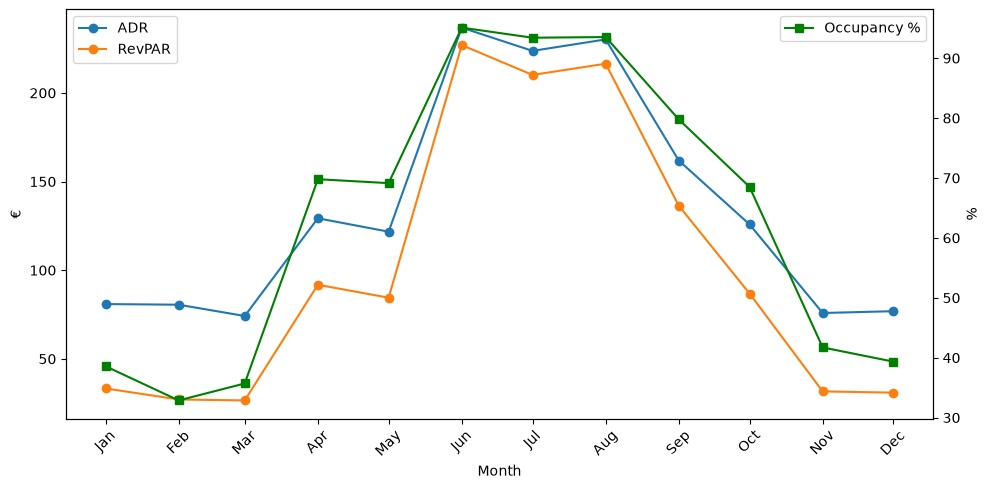

In [ ]:
import matplotlib.dates as mdates
monthly_summary = (
    df.groupby(pd.Grouper(key='Arrival_Date', freq='MS'))
      [['ADR', 'Occupancy_%', 'RevPAR']]
      .mean()
)

fig, ax1 = plt.subplots(figsize=(10, 5))

ax1.plot(monthly_summary.index, monthly_summary['ADR'], marker='o', label='ADR')
ax1.plot(monthly_summary.index, monthly_summary['RevPAR'], marker='o', label='RevPAR')

ax1.xaxis.set_major_locator(mdates.MonthLocator())
ax1.xaxis.set_major_formatter(mdates.DateFormatter('%b'))
plt.xticks(rotation=45)

ax1.set_xlabel('Month')
ax1.set_ylabel('€')
ax1.legend(loc='upper left')

ax2 = ax1.twinx()
ax2.plot(monthly_summary.index, monthly_summary['Occupancy_%'],
         marker='s', color='green', label='Occupancy %')
ax2.set_ylabel('%')
ax2.legend(loc='upper right')

plt.tight_layout()
plt.show()

From January to March, occupancy and ADR remain low and relatively stable, with average occupancy around 36% and ADR around €78. February records the lowest occupancy of the year (32.4%).

Between March and April, occupancy increases sharply from 35.5% to 70%, marking the beginning of the Medium Season. April and May remain relatively stable at around 70% occupancy.

A second significant increase occurs between May and June, when the hotel enters the High Season. June records the highest occupancy (95.55%) and ADR (€237.92) of the year, with July and August remaining at similar levels. From August onwards, performance starts to decline, with a moderate decrease in September and a sharper drop between September and October. From November, the hotel returns to Low Season levels.

RevPAR follows a similar pattern to occupancy and ADR throughout the year, which is consistent with the relationship between these three indicators.

The concentration of high occupancy and ADR between June and August reflects the strong seasonality typical of a beach destination. From a Revenue Management perspective, the transition periods between March–April and May–June are particularly important, as adjusting rates at the right time can help capture the higher willingness to pay during the High Season.


### 4.2. Average Occupancy Rate by Weekday and Month

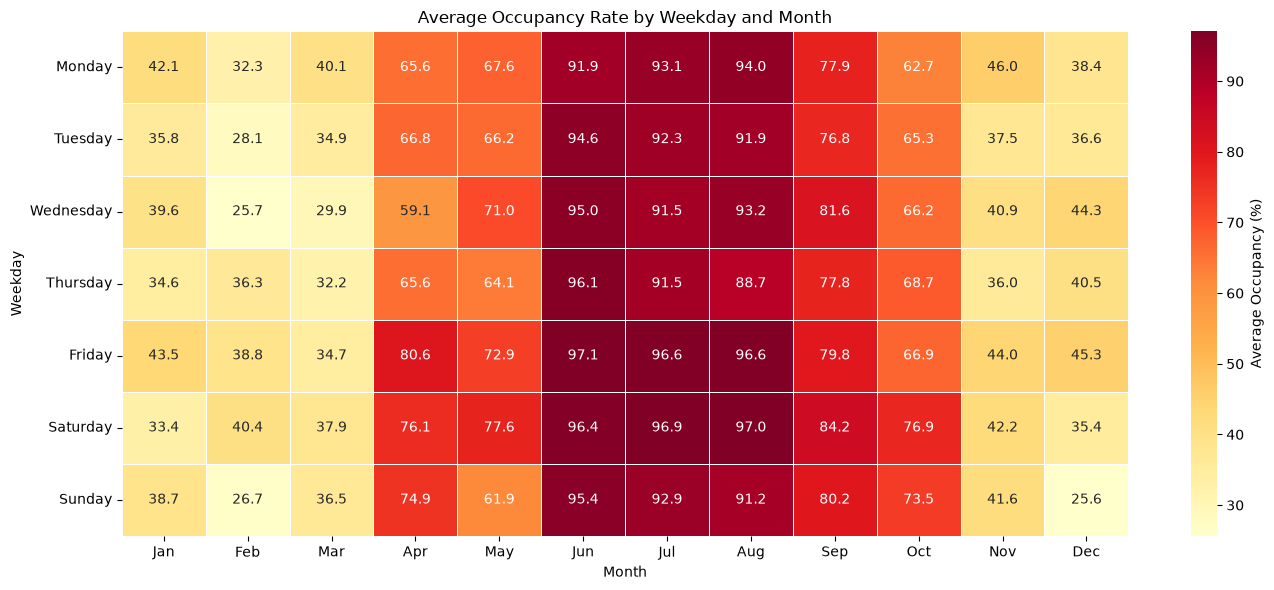

In [ ]:
weekday_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday',
                 'Friday', 'Saturday', 'Sunday']

month_names = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
               'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']

df['Weekday'] = df['Arrival_Date'].dt.day_name()
df['Month'] = df['Arrival_Date'].dt.month

heatmap_data = (
    df.pivot_table(
        index='Weekday',
        columns='Month',
        values='Occupancy_%',
        aggfunc='mean'
    )
    .reindex(index=weekday_order, columns=range(1, 13))
)

heatmap_data.columns = month_names

plt.figure(figsize=(14, 6))

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt='.1f',
    cmap='YlOrRd',
    linewidths=.5,
    cbar_kws={'label': 'Average Occupancy (%)'}
)

plt.title('Average Occupancy Rate by Weekday and Month')
plt.xlabel('Month')
plt.ylabel('Weekday')
plt.tight_layout()
plt.show()

The months with the highest occupancy are June, July and August, with the highest average values concentrated on Fridays and Saturdays. During this period, occupancy ranges from 88.7% to 97.1%.

April, May, September and October show the intermediate levels typical of the Medium Season, with occupancy ranging from 59.1% to 84.2%.

The Low Season (January–March and November–December) has the lowest occupancy levels of the year, ranging from 25.6% to 46%.


### 4.3. ADR by Season

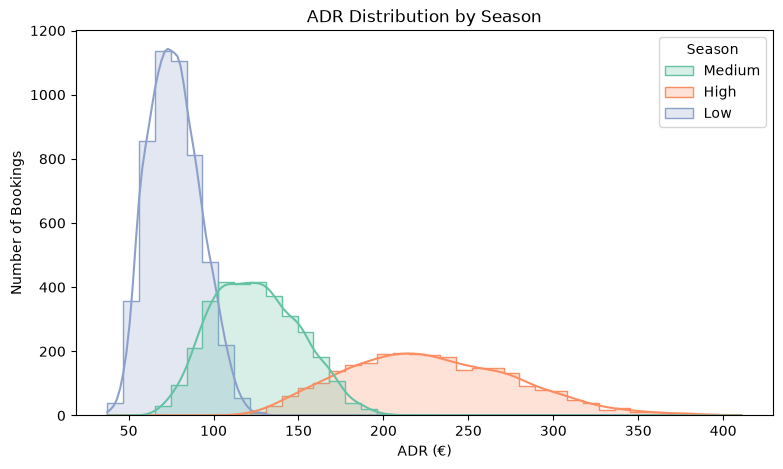

In [ ]:
plt.figure(figsize=(9, 5))
sns.histplot(data=df, x='ADR', hue='Season', bins=40, kde=True, palette='Set2', element='step')
plt.title('ADR Distribution by Season')
plt.ylabel('Number of Bookings')
plt.xlabel('ADR (€)')
plt.show()

In Low Season, ADR ranges from €37.46 to €129.96, with a median of €75.93. In Medium Season, it ranges from €63.72 to €220.53, with a median of €122.91. In High Season, ADR ranges from €118.15 to €410.74, with a median of €224.30.

As the hotel moves into High Season, the number of individual reservations decreases while ADR increases considerably. This pattern is partly explained by a change in length of stay: reservations tend to be longer during High Season, while shorter stays are more common in Low Season. As a result, fewer individual reservations can still generate a similar or higher number of room nights. This contributes to higher revenue per reservation during High Season and helps explain the lower number of bookings despite the higher ADR.


### 4.4. Occupancy by Season

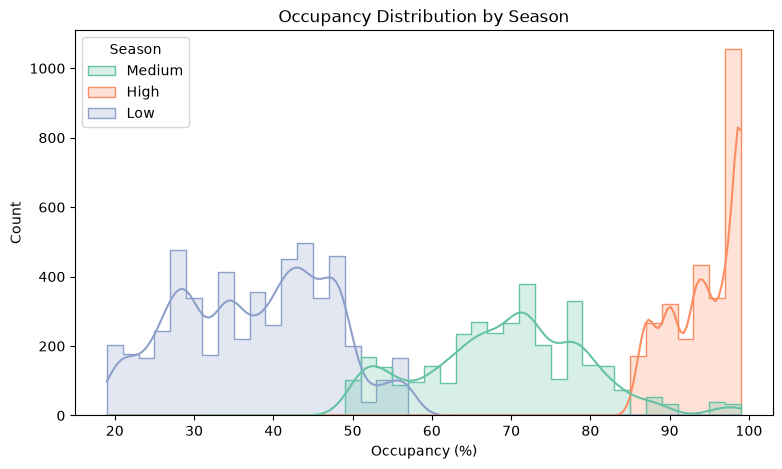

In [ ]:
plt.figure(figsize=(9, 5))
sns.histplot(data=df, x='Occupancy_%', hue='Season', bins=40, kde=True, palette='Set2', element='step')
plt.title('Occupancy Distribution by Season')
plt.xlabel('Occupancy (%)')
plt.show()

In Low Season, occupancy ranges from 18.99% to 60.63%, with a median of 38.82%. In Medium Season, it ranges from 50.36% to 99%, with a median of 70.38%. In High Season, occupancy ranges from 85.43% to 99%, with a median of 94.93%.

During High Season, occupancy remains consistently close to maximum capacity, with 75% of days above 90%. This indicates that the hotel operates close to full capacity during the summer.

From a Revenue Management perspective, however, very high occupancy is not necessarily the optimal objective. If a hotel reaches near 100% occupancy consistently, there may be an opportunity to increase ADR on the days with the highest demand. The objective is not simply to maximize occupancy, but to maximize RevPAR, finding the right balance between occupancy and room rate.


### 4.5. Lead Time by Market Segment

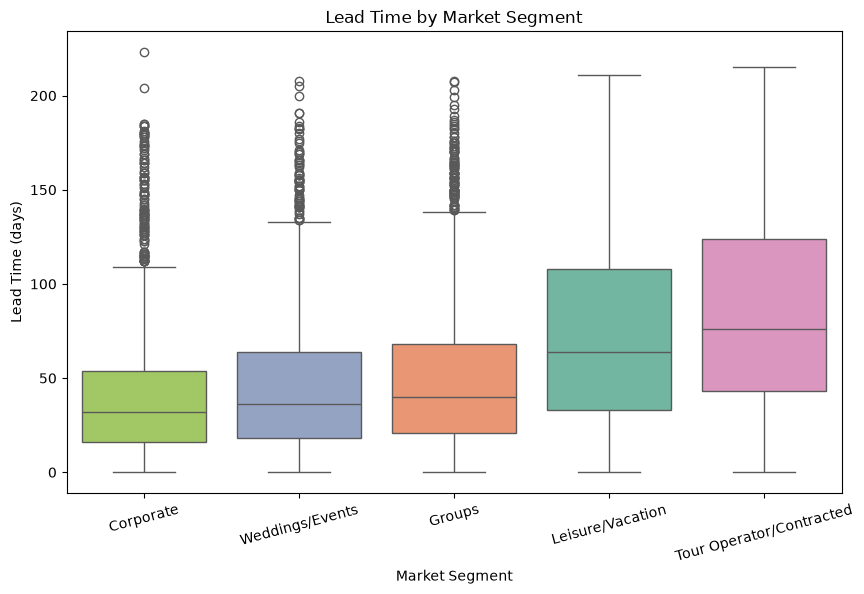

In [ ]:
plt.figure(figsize=(10, 6))
orden = df.groupby('Market_Segment')['Lead_Time_Days'].median().sort_values().index
sns.boxplot(data=df, x='Market_Segment', y='Lead_Time_Days', order=orden, hue='Market_Segment', palette='Set2', legend=False)
plt.title('Lead Time by Market Segment')
plt.xlabel('Market Segment')
plt.ylabel('Lead Time (days)')
plt.xticks(rotation=15)
plt.show()

The average booking lead time is 60 days, with a mode of 48 days. A second relevant peak appears at 0–1 days before arrival, where Corporate reservations are more concentrated. Although Leisure/Vacation is the largest segment in terms of total bookings, Corporate has the highest concentration of last-minute bookings.

The boxplot analysis by market segment shows that Corporate has the lowest average lead time (39.6 days), while Tour Operator/Contracted (83.2 days) and Leisure/Vacation (72.9 days) have the highest values. Corporate, Weddings/Events and Groups also show strongly right-skewed distributions, with outliers reaching up to 223 days.

However, further analysis revealed an important limitation in the dataset. Lead time is mainly determined by the season of the arrival date, rather than independently by market segment. For example, a Corporate reservation arriving during High Season inherits the longer lead time associated with that season, with an average of 128 days compared with 25.7 days in Low Season.

This means that the differences observed between market segments should be interpreted with caution. In a real hotel, Corporate bookings would not necessarily follow the same seasonal lead-time pattern, as business trips may often be booked with shorter notice regardless of the season.


### 4.6. Length of Stay

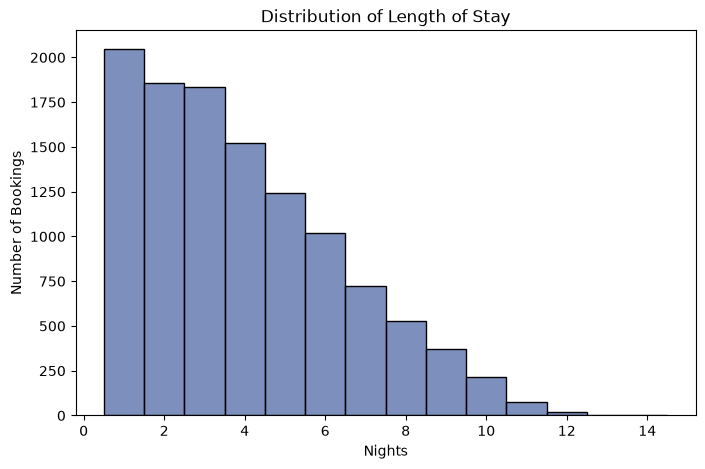

In [ ]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x='Length_of_Stay', discrete=True, color='#516ba7')
plt.title('Distribution of Length of Stay')
plt.xlabel('Nights')
plt.ylabel('Number of Bookings')
plt.show()

### 4.7. Relationship Between Booking Lead Time and ADR

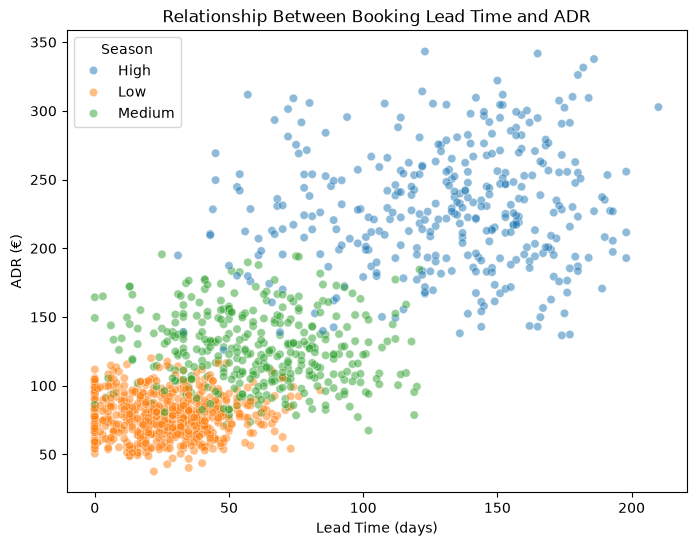

In [ ]:
plt.figure(figsize=(8, 6))
sns.scatterplot(data=df.sample(1500), x='Lead_Time_Days', y='ADR', hue='Season', alpha=0.5)
plt.title('Relationship Between Booking Lead Time and ADR')
plt.xlabel('Lead Time (days)')
plt.ylabel('ADR (€)')
plt.show()

The most common length of stay is 1 night, with a global median of 3 days and a maximum of 14 days during High Season. By season, the median increases from 2 days in Low Season to 4 days in Medium Season and 7 days in High Season. There is no minimum-stay restriction in the dataset, although the minimum stay during High Season is 2 days. This suggests that the high number of 1-night stays is more related to the seasonal pattern than to a specific market segment.

By market segment, Corporate has the lowest median length of stay (2 days), while Tour Operator/Contracted has the highest (5 days). Length of stay also increases together with lead time across seasons. During High Season, longer stays (7.1 nights on average) are combined with earlier bookings (around 130 days in advance), while Low Season is characterised by shorter stays and shorter booking windows. This pattern is consistent with the different types of travel typically associated with each season.


### 4.8. Market Segment

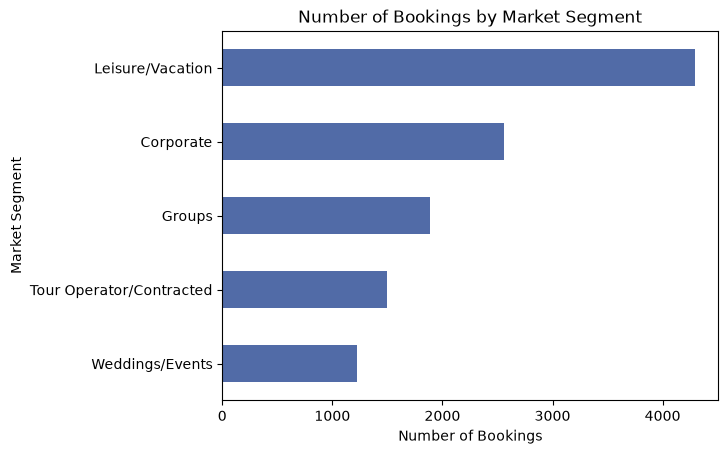

In [ ]:
df['Market_Segment'].value_counts().sort_values(ascending=True).plot.barh(color='#516ba7')
plt.title('Number of Bookings by Market Segment')
plt.xlabel('Number of Bookings')
plt.ylabel('Market Segment')
plt.show()


Leisure/Vacation is the largest market segment, with 4,291 reservations (37% of the total), followed by Corporate with 2,562 reservations (22%) and Groups with 1,889 (16%). Tour Operator/Contracted (1,493) and Weddings/Events (1,227) account for a smaller share of the total bookings.

The predominance of the Leisure/Vacation segment is consistent with the profile of a beach resort. The relatively large share of Corporate bookings also shows that the simulated hotel attracts a significant business segment, although its seasonal distribution should be considered when interpreting this result.


### 4.9. Number of Bookings by Season

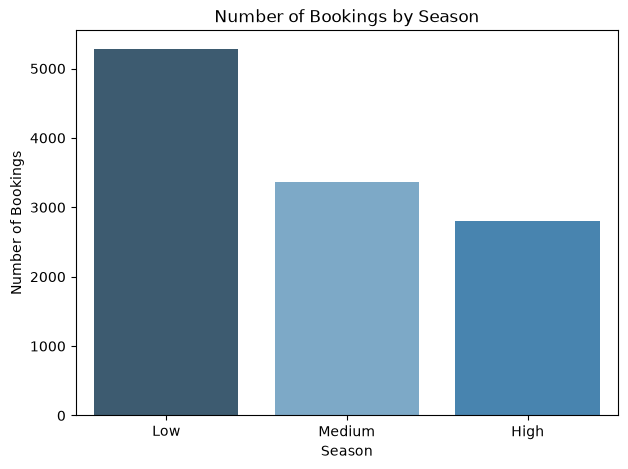

In [ ]:
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x='Season', order=['Low', 'Medium', 'High'], hue='Season', palette='Blues_d')
plt.title('Number of Bookings by Season')
plt.xlabel('Season')
plt.ylabel('Number of Bookings')
plt.show()

The number of reservations is 5,284 in Low Season, 3,372 in Medium Season and 2,806 in High Season. This shows an inverse pattern between booking volume and ADR: the season with the lowest average rate has almost twice as many individual reservations as the season with the highest rate.

This pattern is partly explained by length of stay. Shorter stays in Low Season generate more individual reservations for a similar number of room nights, while longer stays are more common in High Season.


### 4.10. ADR by Season

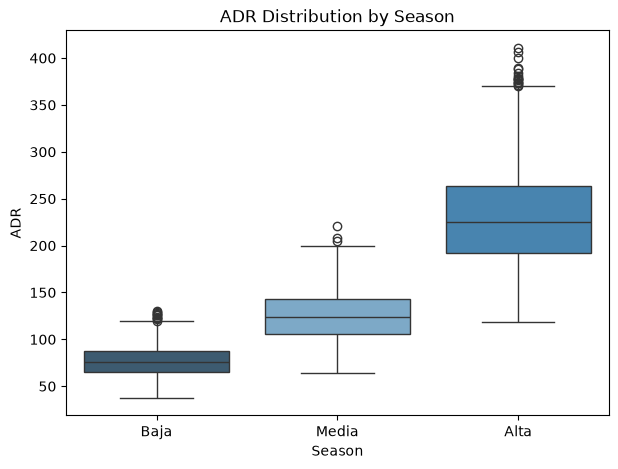

In [ ]:
plt.figure(figsize=(7, 5))
sns.boxplot(data=df, x='Season', y='ADR', order=['Baja', 'Media', 'Alta'], hue='Season', palette='Blues_d', legend=False)
plt.title('ADR Distribution by Season')
plt.show()

As the season progresses, not only does average ADR increase, but its dispersion also becomes larger. The interquartile range (IQR) increases from €21.11 in Low Season to €36.87 in Medium Season and €68.37 in High Season, meaning that the size of the box in the boxplot more than triples between Low and High Season.

The higher dispersion in High Season suggests a more differentiated pricing pattern. Instead of applying relatively uniform rates, as observed in Low Season, the hotel appears to use a wider range of prices when demand is higher. This could be related to factors such as room type, day of the week, events or booking lead time, although these factors would need to be analysed separately to confirm their impact.

High Season also shows a long lower whisker, reaching approximately €118, with very few lower outliers. At the upper end, several outliers exceed €380, representing exceptionally high ADR values that may be associated with specific high-demand dates or events.


### 4.11. ADR with Event and No Event

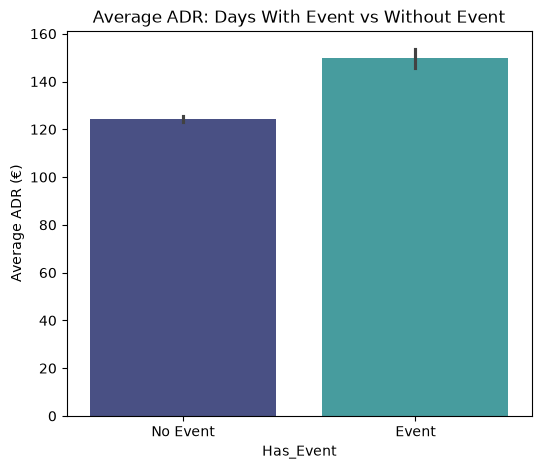

In [ ]:
df['Has_Event'] = df['Event_Type'].apply(
    lambda x: 'No Event' if x == 'Sin Evento' or pd.isna(x) or str(x).strip() == '' else 'Event'
    )


plt.figure(figsize=(6, 5))
sns.barplot(data=df, x='Has_Event', y='ADR', estimator='mean', hue='Has_Event', palette='mako', legend=False)
plt.title('Average ADR: Days With Event vs Without Event')
plt.ylabel('Average ADR (€)')
plt.show()

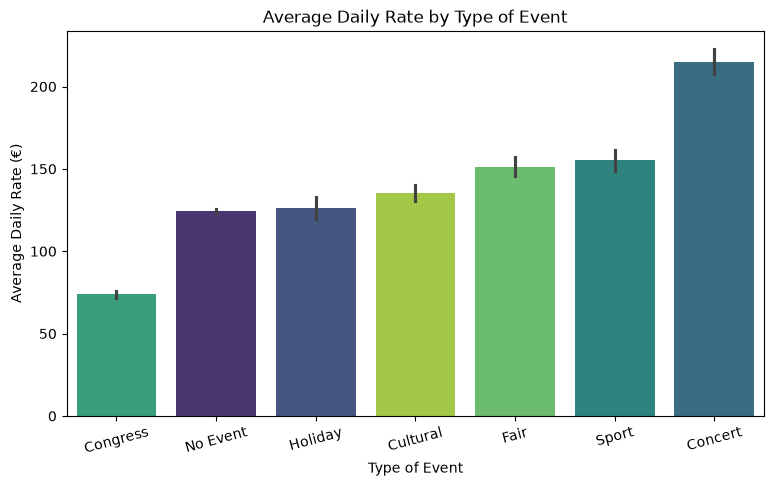

In [ ]:
plt.figure(figsize=(9, 5))
orden = df[df['Event_Type'] != 'Sin Evento'].groupby('Event_Type')['ADR'].mean().sort_values().index

sns.barplot(
    data=df[df['Event_Type'] != 'Sin Evento'],
    x='Event_Type', y='ADR',
    order=orden,
    hue='Event_Type', palette='viridis', legend=False,
    estimator='mean'
)
plt.title('Average Daily Rate by Type of Event')
plt.xlabel('Type of Event')
plt.ylabel('Average Daily Rate (€)')
plt.xticks(rotation=15)
plt.show()

Average ADR is €124.45 on days without an event, compared with €149.11 on days with an event, representing an increase of approximately 20%.

However, the effect varies considerably depending on the type of event:

* Concerts (€213.23) and Sports events (€154.71) show the highest ADR values.
* Fairs (€150.74), Cultural events (€134.93) and Holidays (€126.13) show more moderate values.
* Congresses (€73.88) have a lower ADR than days without events.

This suggests that the relationship between events and ADR depends on the type of event rather than simply on the presence of an event. Concerts and sporting events show the strongest association with higher ADR in the simulated dataset and could therefore represent potential opportunities for more dynamic pricing.

However, these results should be interpreted as an association rather than a causal effect, since other factors such as seasonality and demand levels may also influence ADR.


### 4.12. Bookings by Distribution Channel

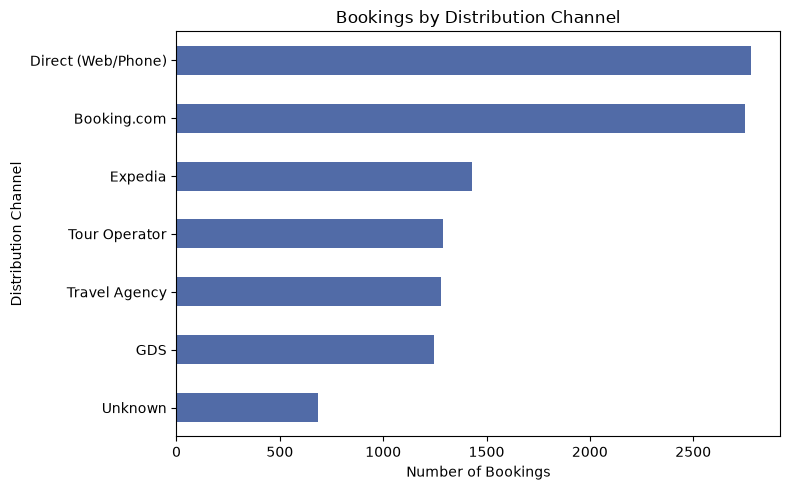

In [ ]:
df['Distribution_Channel'].value_counts().sort_values().plot.barh(figsize=(8, 5), color='#516ba7')
plt.xlabel('Number of Bookings')
plt.title('Bookings by Distribution Channel')
plt.ylabel('Distribution Channel')
plt.tight_layout()
plt.show()

Direct bookings are the most common distribution channel, followed closely by Booking.com, with only 30 reservations separating the two. Both channels therefore have very similar booking volumes.

Expedia ranks third with 1,428 reservations, followed by Tour Operator (1,288), Travel Agency (1,282) and GDS (1,245), which have relatively similar booking volumes.

The similar volume between Direct and Booking.com suggests a relatively balanced distribution mix in the simulated dataset. However, the dataset does not include commission costs or profitability by channel, so it is not possible to determine which channel is more profitable or whether the direct channel represents a stronger commercial strategy.


### 4.13. Cancellation Rate by Market Segment

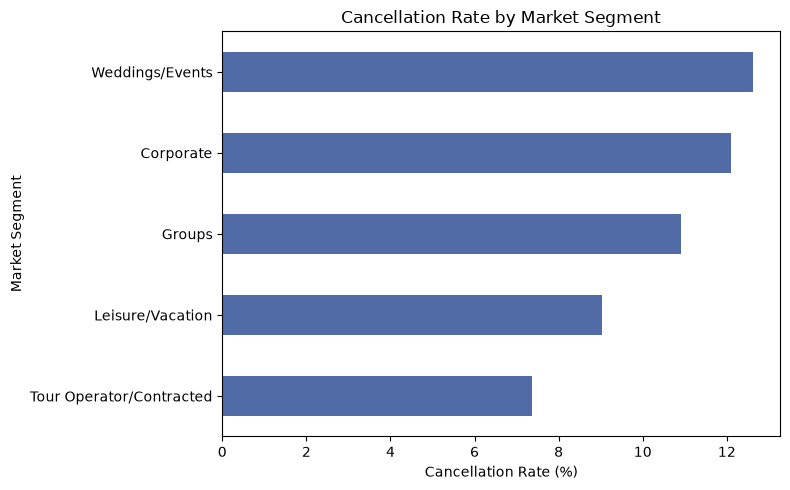

In [ ]:
cancellation_rate = df.groupby('Market_Segment')['Is_Cancelled'].mean().sort_values() * 100

plt.figure(figsize=(8, 5))
cancellation_rate.plot.barh(color='#516ba7')
plt.xlabel('Cancellation Rate (%)')
plt.title('Cancellation Rate by Market Segment')
plt.ylabel('Market Segment')
plt.tight_layout()
plt.show()

Weddings/Events (12.63%) and Corporate (12.10%) have the highest cancellation rates, while Tour Operator/Contracted (7.37%) and Leisure/Vacation (9.04%) show the lowest rates.

However, this pattern is strongly influenced by seasonality. The segments with the highest cancellation rates also have a higher concentration of bookings in Low Season: 73.9% for Corporate and 61.4% for Weddings/Events. Low Season also has the highest overall cancellation rate. In contrast, Tour Operator/Contracted has a larger share of bookings during High Season (46.2%), which has the lowest cancellation rate.

Therefore, the differences in cancellation rates between market segments appear to be strongly influenced by their seasonal distribution, rather than being solely related to the behaviour of each customer segment.
